# SD3.5 Image Visualization with QWEN Predictions

Visualize images from standard or custom SD3.5 with QWEN reason predictions.

Shows:
- Generated image
- Phrase and prompt used
- QWEN full answer and final YES/NO judgement

In [1]:
import torch
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
from PIL import Image
import textwrap

In [2]:
# Configuration
BASELINE_QWEN_DIR = Path("../x7-z1-qwen_small/qwen_outputs_standard_sd/reason")
BASELINE_TENSORS_BASE = Path("../x5.5-prompts_sd35_output")
CUSTOM_QWEN_DIR = Path("../x7-z1-qwen_small/qwen_outputs")
CUSTOM_OUTPUT_BASE = Path("../z0-custom_sd35_clic/custom_sd35_outputs")

# Baseline standard SD3.5 tensor directories
BASELINE_TENSOR_DIRS = [
    BASELINE_TENSORS_BASE / "sd35_output_left_right_above",
    BASELINE_TENSORS_BASE / "sd35_output_below_over_under",
    BASELINE_TENSORS_BASE / "sd35_output_behind_on_front",
    BASELINE_TENSORS_BASE / "sd35_output_not_without",
    BASELINE_TENSORS_BASE / "sd35_output_holding_touching_not",
    BASELINE_TENSORS_BASE / "sd35_output_top",
    BASELINE_TENSORS_BASE / "sd35_output_between_inside_outside"
]

# Custom SD3.5 tensor directories
CUSTOM_OUTPUT_DIRS = [
    CUSTOM_OUTPUT_BASE / "custom_sd35_output_left-right-above-top",
    CUSTOM_OUTPUT_BASE / "custom_sd35_output_below-under-over",
    CUSTOM_OUTPUT_BASE / "custom_sd35_output_behind-on-infrontof",
    CUSTOM_OUTPUT_BASE / "custom_sd35_output_andnot-without",
    CUSTOM_OUTPUT_BASE / "custom_sd35_output_bw-inside-outside-nholding-ntouch-not-without",
    CUSTOM_OUTPUT_BASE / "custom_sd35_output_closeby-far",
    CUSTOM_OUTPUT_BASE / "custom_sd35_output_sitting-running-standing"
]

In [3]:
def load_baseline_data():
    """Load baseline SD3.5 QWEN evaluations."""
    data = {}
    csv_files = list(BASELINE_QWEN_DIR.glob("*_qwen_reason_*.csv"))
    
    for csv_file in csv_files:
        phrase = csv_file.stem.split("_qwen_reason_")[0]
        df = pd.read_csv(csv_file)
        data[phrase] = df
    
    return data

def load_custom_data():
    """Load custom SD3.5 QWEN evaluations."""
    data = {}
    
    if CUSTOM_QWEN_DIR.exists():
        csv_files = list(CUSTOM_QWEN_DIR.glob("*_custom_qwen_reason_*.csv"))
        
        for csv_file in csv_files:
            phrase = csv_file.stem.split("_custom_qwen_reason_")[0]
            df = pd.read_csv(csv_file)
            data[phrase] = df
    
    return data

In [4]:
def load_image_tensor(tensor_file, tensor_index, model_type='baseline'):
    """Load image from tensor file."""
    tensor_path = None
    
    if model_type == 'baseline':
        # Search in baseline output directories
        for dir_path in BASELINE_TENSOR_DIRS:
            potential_path = dir_path / "tensors" / tensor_file
            if potential_path.exists():
                tensor_path = potential_path
                break
    else:
        # Search in custom output directories
        for dir_path in CUSTOM_OUTPUT_DIRS:
            potential_path = dir_path / "tensors" / tensor_file
            if potential_path.exists():
                tensor_path = potential_path
                break
    
    if tensor_path is None:
        return None
    
    try:
        tensors = torch.load(tensor_path, map_location='cpu', weights_only=False)
        
        # Handle different tensor file formats
        if isinstance(tensors, dict) and 'images' in tensors:
            # Dictionary format with 'images' key
            images = tensors['images']
            if tensor_index < len(images):
                img_tensor = images[tensor_index]
            else:
                return None
        elif isinstance(tensors, list):
            # List format
            if tensor_index < len(tensors):
                img_tensor = tensors[tensor_index]
            else:
                return None
        else:
            # Single tensor
            img_tensor = tensors
        
        # Auto-detect tensor range and convert to [0, 255]
        tensor_min = img_tensor.min().item()
        tensor_max = img_tensor.max().item()
        
        img_np = img_tensor.permute(1, 2, 0).numpy()
        
        if tensor_min >= -0.1 and tensor_max <= 1.1:
            # Tensor is in [0, 1] range
            img_array = (img_np * 255).astype(np.uint8)
        elif tensor_min >= -1.1 and tensor_max <= 1.1:
            # Tensor is in [-1, 1] range
            img_array = ((img_np + 1) * 127.5).astype(np.uint8)
        else:
            # Unexpected range, try to normalize
            img_array = ((img_np - tensor_min) / (tensor_max - tensor_min) * 255).astype(np.uint8)
        
        return Image.fromarray(img_array)
        
    except Exception as e:
        print(f"Error loading {tensor_file}[{tensor_index}]: {e}")
        return None
    
    return None

In [5]:
# Load data
print("Loading baseline SD3.5 data...")
baseline_data = load_baseline_data()
print(f"Loaded {len(baseline_data)} phrases\n")

print("Loading custom SD3.5 data...")
custom_data = load_custom_data()
print(f"Loaded {len(custom_data)} phrases")

# Helper function to list available phrases
def list_phrases(model_type='baseline'):
    """List all available phrases for a model type."""
    data = baseline_data if model_type == 'baseline' else custom_data
    print(f"\nAvailable phrases for {model_type} model:")
    for phrase in sorted(data.keys()):
        print(f"  - {phrase} ({len(data[phrase])} images)")

Loading baseline SD3.5 data...
Loaded 16 phrases

Loading custom SD3.5 data...
Loaded 22 phrases


In [6]:
def visualize_images(model_type='baseline', phrase='above', n_images=10, start_idx=0, filter_answer=None):
    """
    Visualize images for a specific model and phrase.
    
    Args:
        model_type: 'baseline' or 'custom'
        phrase: The phrase to visualize (e.g., 'above', 'below', 'holding')
        n_images: Number of images to display (default: 10)
        start_idx: Starting index in the dataframe (default: 0)
        filter_answer: Filter by answer 'YES', 'NO', or None for all (default: None)
    """
    # Get data
    if model_type == 'baseline':
        data = baseline_data
    elif model_type == 'custom':
        data = custom_data
    else:
        return ValueError("Model type unrecognized. Available options: 'baseline', 'custom'.")
    
    if phrase not in data:
        print(f"Phrase '{phrase}' not found in {model_type} data.")
        print(f"Available phrases: {sorted(data.keys())}")
        return
    
    df = data[phrase].copy()
    
    # Filter by answer if specified
    if filter_answer:
        df = df[df['answer'].str.upper() == filter_answer.upper()].reset_index(drop=True)
        if len(df) == 0:
            print(f"No images with answer '{filter_answer}' for phrase '{phrase}'")
            return
    
    # Get subset
    end_idx = min(start_idx + n_images, len(df))
    subset_df = df.iloc[start_idx:end_idx]
    n_show = len(subset_df)
    
    if n_show == 0:
        print(f"No images to show (total available: {len(df)})")
        return
    
    print(f"Showing {n_show} images from {model_type} model, phrase: '{phrase}'")
    print(f"(Images {start_idx+1}-{end_idx} of {len(df)} total)\n")
    
    # Display images one by one in rows
    for idx, (_, row) in enumerate(subset_df.iterrows()):
        img_idx = start_idx + idx + 1
        
        # Handle both single-class (action words) and two-class (relational) prompts
        if 'class2' in row and pd.notna(row.get('class2')):
            # Two-class relational prompt: "cat above dog"
            prompt = f"{row['class1']} {row['phrase'].replace('_', ' ')} {row['class2']}"
        else:
            # Single-class action prompt: "a photo of a cat sitting"
            prompt = f"a photo of a {row['class1']} {row['phrase'].replace('_', ' ')}"
        
        answer = row['answer']
        answer_color = 'green' if answer == 'YES' else 'red'
        
        # Print text information
        print(f"IMAGE #{img_idx}")
        print(f"Prompt: {prompt}")
        print(f"\nQWEN Short Answer: {answer}")
        print(f"\nQWEN Full Reasoning:")
        wrapped_answer = textwrap.fill(row['full_answer'], width=100)
        print(wrapped_answer)
        
        # Display image
        fig, ax = plt.subplots(1, 1, figsize=(8, 8))
        
        # Load and display image
        img = load_image_tensor(row['tensor_file'], row['tensor_index'], model_type)
        
        if img is not None:
            ax.imshow(img)
            title = f"Image #{img_idx} | {answer}"
            ax.set_title(title, fontsize=14, weight='bold', color=answer_color, pad=10)
        else:
            ax.text(0.5, 0.5, f"Image not found:\n{row['tensor_file']}", 
                   ha='center', va='center', fontsize=10, color='red')
            ax.set_title(f"Image #{img_idx} - NOT FOUND", fontsize=14, weight='bold', color='red')
        
        ax.axis('off')
        plt.tight_layout()
        plt.show()
        
    print(f"Completed displaying {n_show} images")

Use the `visualize_images()` function to view images with their prompts and QWEN answers.

**Parameters:**
- `model_type`: 'baseline' or 'custom'
- `phrase`: The phrase to visualize (e.g., 'above', 'below', 'holding')
- `n_images`: Number of images to display (default: 10)
- `start_idx`: Starting index (default: 0)
- `filter_answer`: Filter by 'YES', 'NO', or None for all (default: None)

**Helper function:**
- `list_phrases(model_type)`: List all available phrases for a model

In [7]:
list_phrases('custom')


Available phrases for custom model:
  - above (100 images)
  - and_not (200 images)
  - behind (100 images)
  - below (100 images)
  - between (100 images)
  - closeby (100 images)
  - far_from (100 images)
  - holding (100 images)
  - in_front_of (100 images)
  - not_holding (100 images)
  - not_touching (100 images)
  - on (100 images)
  - on_top_of (100 images)
  - outside (100 images)
  - over (100 images)
  - running (100 images)
  - sitting (100 images)
  - standing (100 images)
  - to_the_left_of (100 images)
  - to_the_right_of (100 images)
  - touching (100 images)
  - under (100 images)


Showing 15 images from custom model, phrase: 'between'
(Images 1-15 of 100 total)

IMAGE #1
Prompt: giraffe between hair drier

QWEN Short Answer: NO

QWEN Full Reasoning:
Step 1: The image clearly shows a giraffe's head and neck in the center, surrounded by multiple hair
dryers. The giraffe is visible, and several hair dryers are also visible, though they are arranged
around the giraffe rather than interacting with it.  Step 2: The giraffe is not between the hair
dryers. Instead, the hair dryers are positioned around the giraffe, appearing to be on all sides.
There is no single hair dryer on either side of the giraffe that would create a scenario where the
giraffe is "between" them. The arrangement is radial, not linear.  Step 3: The image is clear enough
to determine the spatial layout. The giraffe is not positioned between two hair dryers in a way that
would satisfy the description.  Conclusion: No


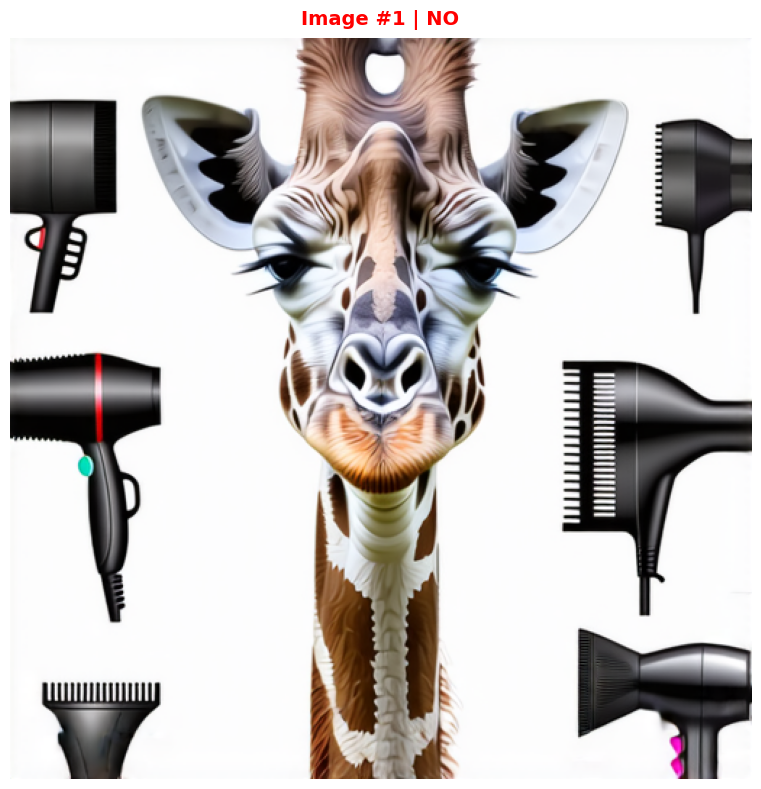

IMAGE #2
Prompt: broccoli between skis

QWEN Short Answer: NO

QWEN Full Reasoning:
Step 1: The image clearly shows a broccoli. There are no skis visible in the image.  Step 2: Since
skis are not present in the image, there is no spatial relationship between the broccoli and skis.
Step 3: The image is not ambiguous; it is clear that skis are absent.  Conclusion: No


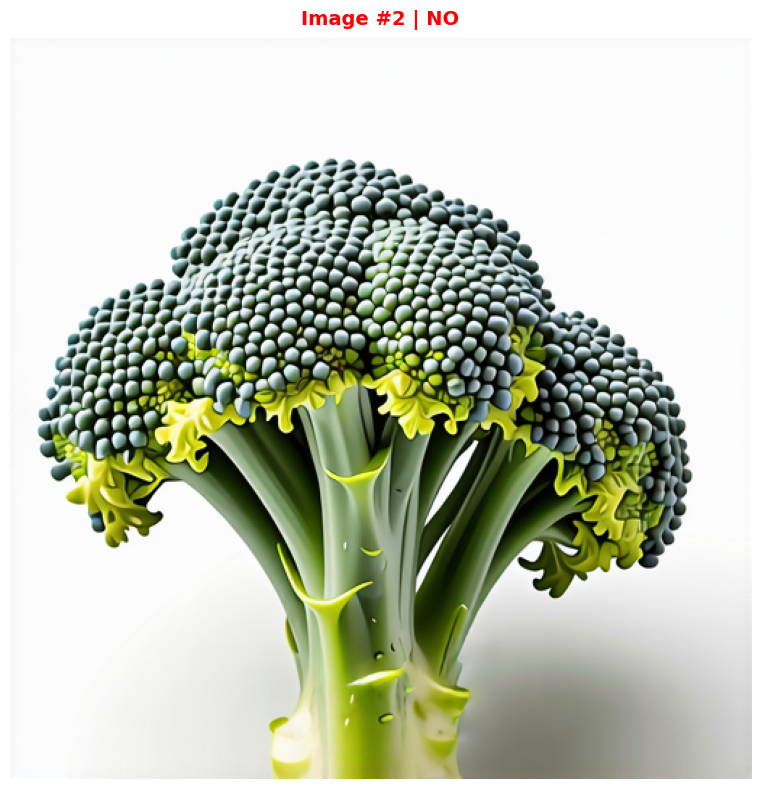

IMAGE #3
Prompt: book between sports ball

QWEN Short Answer: NO

QWEN Full Reasoning:
Step 1: The image clearly shows an open book in the center and a sports ball (specifically, a
football) on the left side. The book is fully visible with text and an illustration, and the
football is partially visible, positioned to the left of the book.  Step 2: The sports ball is
located to the left of the book, and there is no indication that the book is physically between the
ball and any other object. Instead, the ball is outside the book, and the book is open in the middle
of the frame. The book is not sandwiched between two sports balls or between a sports ball and
another object.  Step 3: The image is clear and the spatial arrangement is distinct. There is no
ambiguity in the positioning of the objects.  Conclusion: No


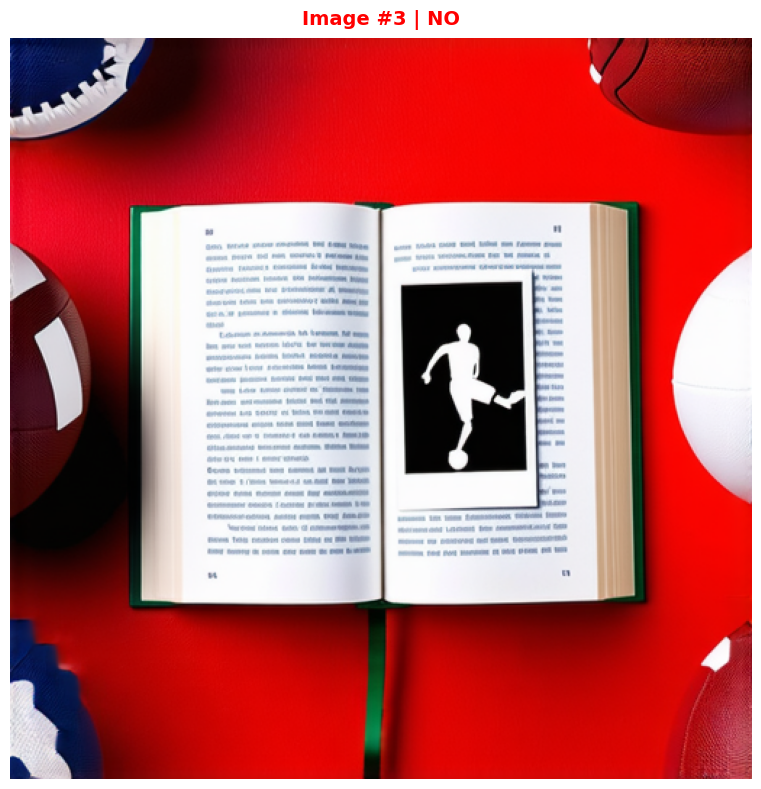

IMAGE #4
Prompt: bench between cow

QWEN Short Answer: YES

QWEN Full Reasoning:
Step 1: The image clearly shows two cows, one on the left and one on the right, standing on a
horizontal structure. This structure appears to be a bench or a platform with legs.  Step 2: The
bench is positioned between the two cows. The cow on the left is standing on the left side of the
bench, and the cow on the right is standing on the right side of the bench. Therefore, the bench is
spatially located between them.  Step 3: The image is clear enough to identify both the cows and the
bench, and their spatial relationship is unambiguous.  Conclusion: Yes


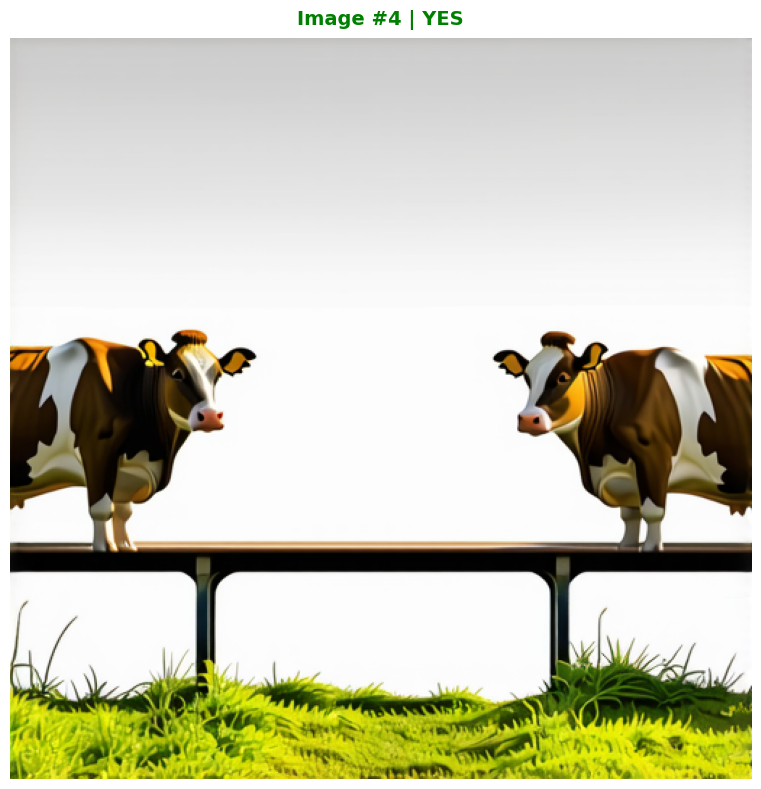

IMAGE #5
Prompt: computer keyboard between skateboard

QWEN Short Answer: NO

QWEN Full Reasoning:
Step 1: The image clearly shows a computer keyboard with blue and white keys in the center.
Surrounding the keyboard are several skateboard decks, visible at the top and bottom of the image.
Step 2: The keyboard is positioned in the center, and the skateboard decks are arranged around it,
above and below. There is no physical overlap or direct contact between the keyboard and any
skateboard; they are separate objects arranged in a pattern.   Step 3: The objects are clearly
visible and their arrangement is distinct. The keyboard is not between two skateboards in a spatial
sense (e.g., sandwiched or aligned horizontally between them), nor is it physically between them.
Conclusion: No


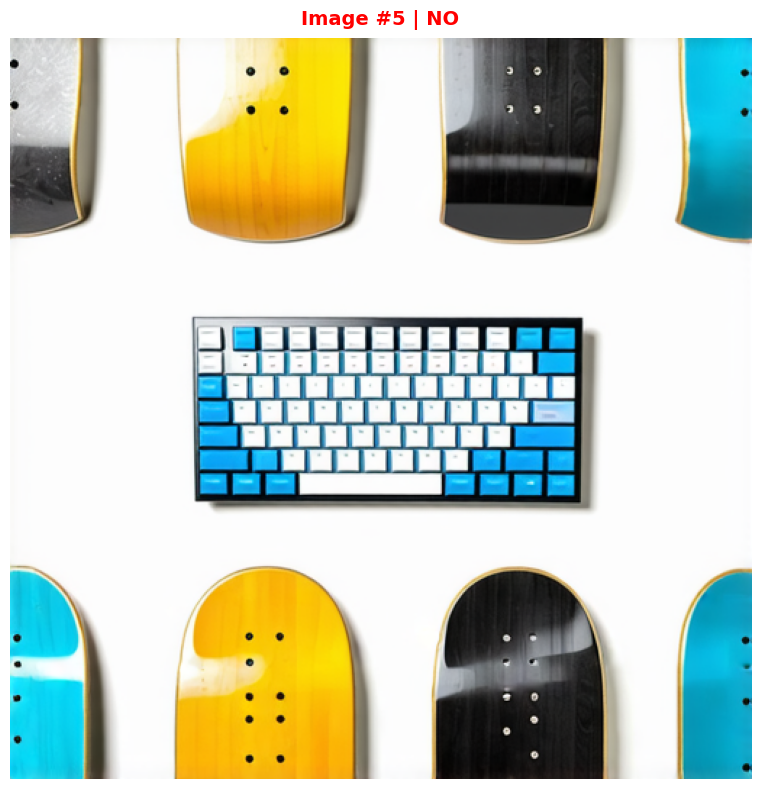

IMAGE #6
Prompt: toilet between potted plant

QWEN Short Answer: YES

QWEN Full Reasoning:
Step 1: The image clearly shows a white toilet with its lid open and multiple potted plants. There
is a large potted plant with broad green leaves to the left of the toilet, another potted plant with
trailing green leaves on top of the toilet tank, and a third potted plant to the right of the
toilet.  Step 2: The toilet is positioned between the potted plant on the left and the potted plant
on the right. The plant on top of the tank is above the toilet, not to its side. The spatial
arrangement confirms that the toilet is situated between two potted plants on either side.  Step 3:
The image is clear and the objects and their positions are well-defined.  Conclusion: Yes


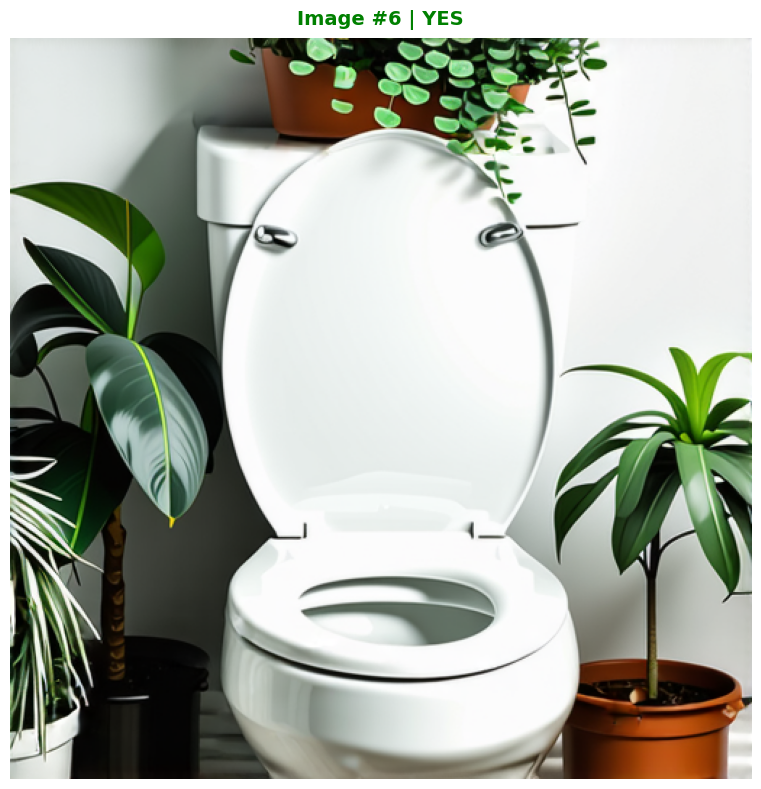

IMAGE #7
Prompt: oven between vase

QWEN Short Answer: YES

QWEN Full Reasoning:
Step 1: The image clearly shows a white oven with a stovetop and an open oven door. There are also
several vases visible: a black ribbed vase and a red vase on the countertop to the left and right of
the oven, and a white ribbed vase in the foreground on the left.  Step 2: The oven is positioned in
the center of the image, with a black vase to its immediate left and a red vase to its immediate
right on the same countertop surface. The white vase in the foreground is in front of the oven but
not directly beside it.  Step 3: The image is clear and the spatial relationships are unambiguous.
Conclusion: Yes


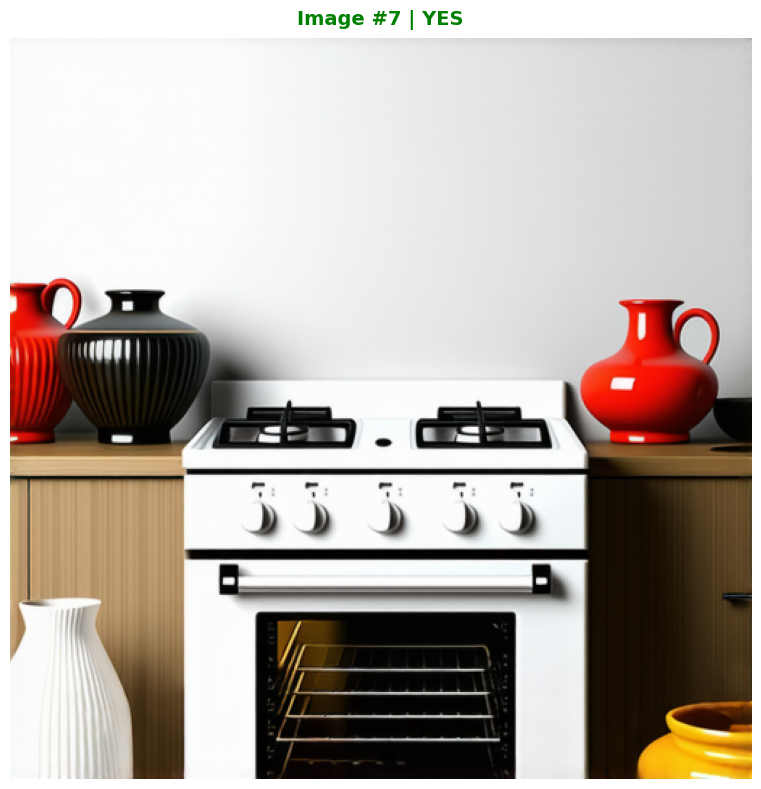

IMAGE #8
Prompt: bed between book

QWEN Short Answer: NO

QWEN Full Reasoning:
Step 1: The image clearly shows a bed with white sheets and pillows, and an open book resting on the
bed. Both objects are visible.  Step 2: The book is placed directly on the bed, in the center,
between the two white pillows. The bed is not between the book; rather, the book is on the bed.
Step 3: The spatial relationship is clear and unambiguous.  Conclusion: No


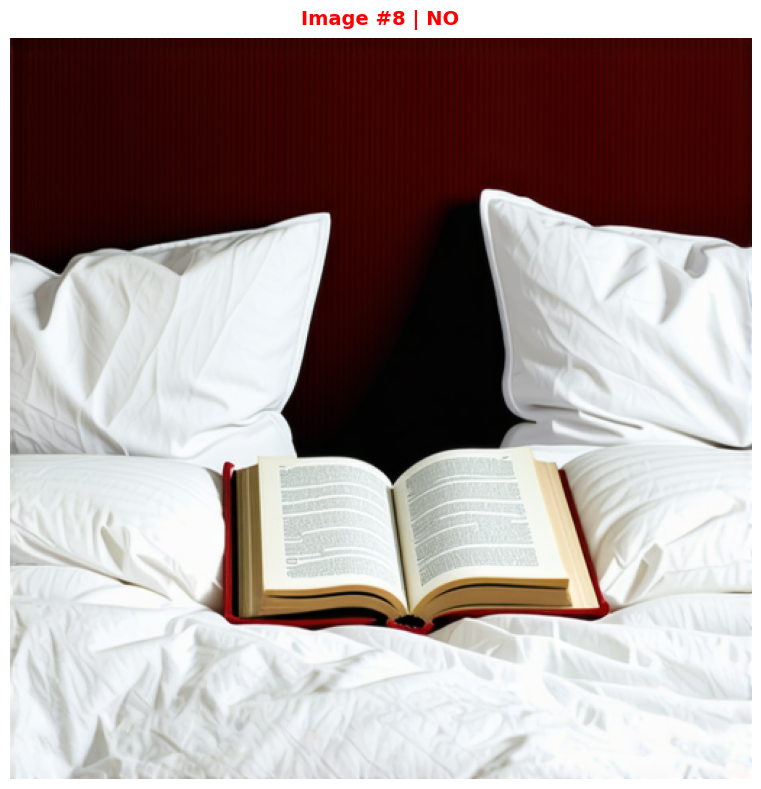

IMAGE #9
Prompt: cell phone between bear

QWEN Short Answer: YES

QWEN Full Reasoning:
Step 1: The image clearly shows a cell phone in the center, and a bear is visible on both sides of
the phone, as well as on the phone's screen.   Step 2: The cell phone is positioned between two bear
images — one on the left and one on the right — which are part of the overall composition. The bear
on the screen is a digital image displayed on the phone.   Step 3: The scene is not ambiguous; the
cell phone is visually and spatially located between the two larger bear images.    Conclusion: Yes


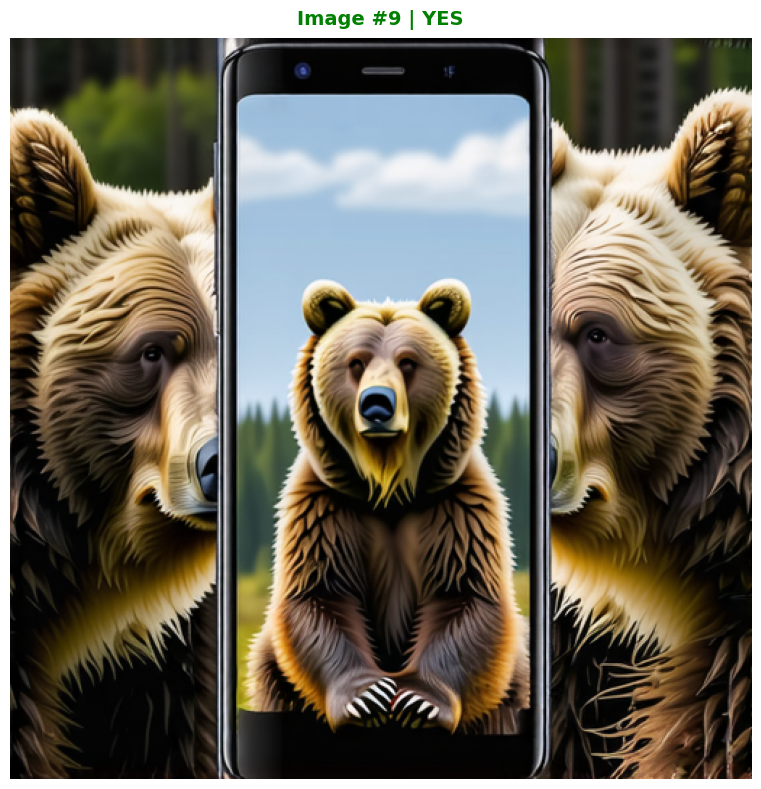

IMAGE #10
Prompt: sports ball between refrigerator

QWEN Short Answer: YES

QWEN Full Reasoning:
Step 1: The image clearly shows a soccer ball and a refrigerator. The soccer ball is in the
foreground, and the refrigerator is visible in the background, with its door partially open.  Step
2: The soccer ball is positioned in the gap between the refrigerator door and the refrigerator
frame. It is physically wedged between the two, making it appear as if it is 'between' them.  Step
3: The objects are clearly visible, and their spatial relationship is unambiguous.  Conclusion: Yes


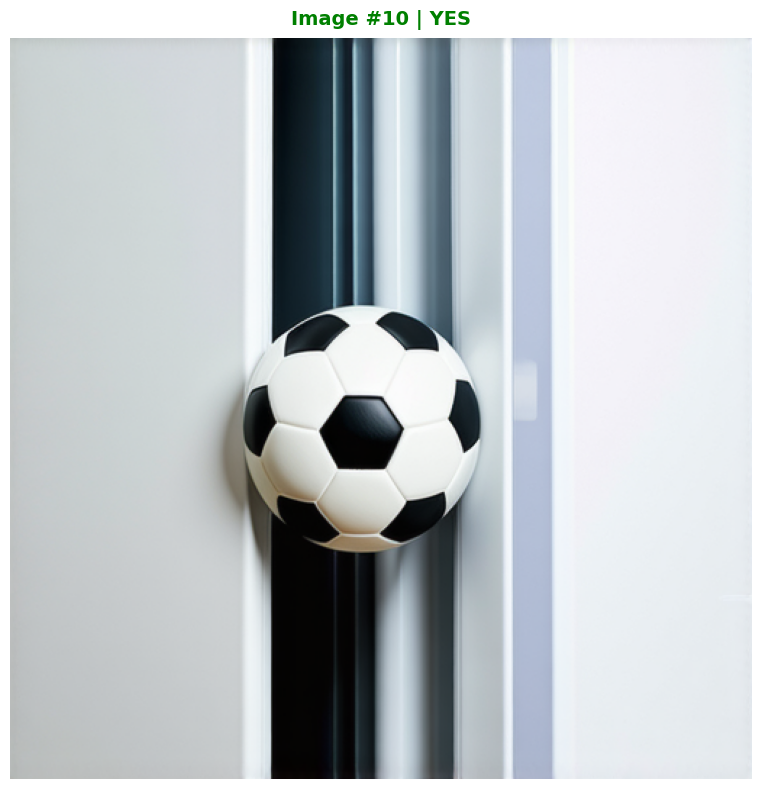

IMAGE #11
Prompt: baseball bat between dog

QWEN Short Answer: YES

QWEN Full Reasoning:
Step 1: The image clearly shows a baseball bat and two dogs. The bat is positioned horizontally, and
the dogs are on either side of it, facing each other.  Step 2: The baseball bat is located between
the two dogs. The black dog on the left has its mouth on the barrel end of the bat, and the brown
and white dog on the right has its mouth on the handle end. The bat is physically situated between
the two animals.  Step 3: The image is clear and unambiguous. The objects and their spatial
relationship are distinct.  Conclusion: Yes


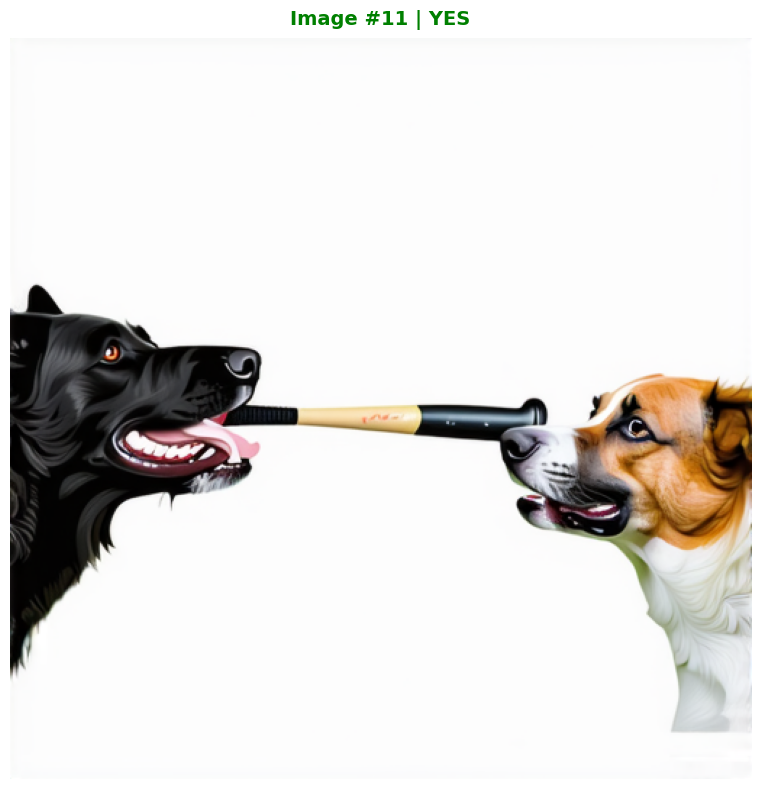

IMAGE #12
Prompt: orange between traffic light

QWEN Short Answer: NO

QWEN Full Reasoning:
Step 1: The image clearly shows a traffic light with two illuminated lights. The top light is a
glowing orange, and the bottom light is also orange. The texture of the top light's surface is
distinctly dimpled, resembling the peel of an orange fruit.  Step 2: The traffic light fixture is
positioned vertically. The top light is above the bottom light. The object that looks like an orange
is not a separate fruit placed between the lights, but rather the lens of the top traffic light
itself, which is lit and has an orange color and texture.  Step 3: The image is clear enough to
identify the objects. The "orange" is not a separate object but is the light source within the
traffic signal. There is no actual orange fruit present between the lights.  Conclusion: No


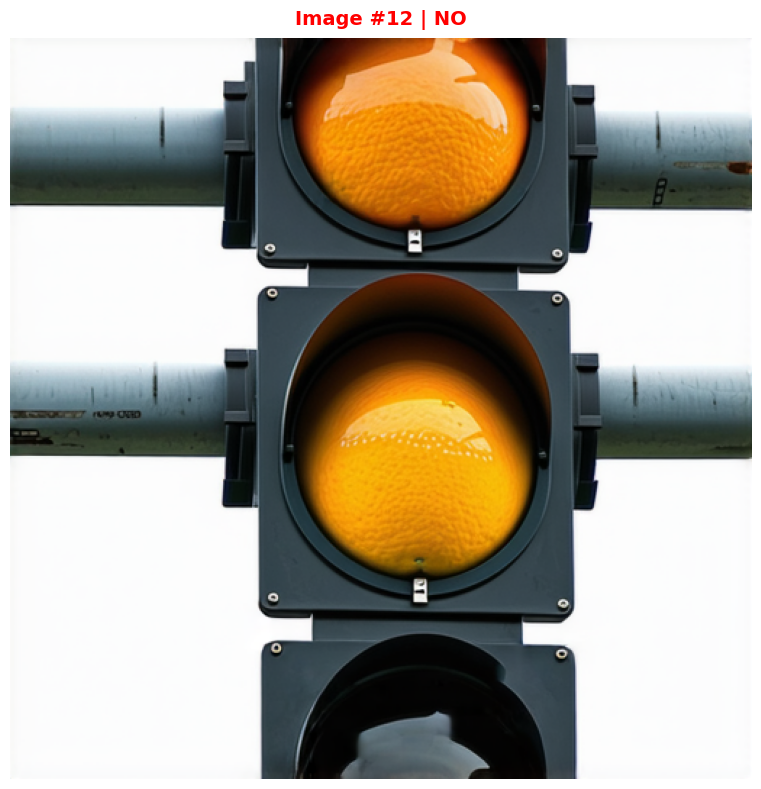

IMAGE #13
Prompt: teddy bear between orange

QWEN Short Answer: YES

QWEN Full Reasoning:
Step 1: The image clearly shows a white teddy bear and several oranges. Both objects are visible and
well-defined.  Step 2: The teddy bear is positioned in the center of the frame, surrounded by
oranges on all sides. It is nestled among the oranges, with some oranges directly adjacent to its
body and limbs.  Step 3: The spatial relationship is clear—the teddy bear is between the oranges,
not just near them. The arrangement shows the bear surrounded by the fruit, indicating it is located
between them.  Conclusion: Yes


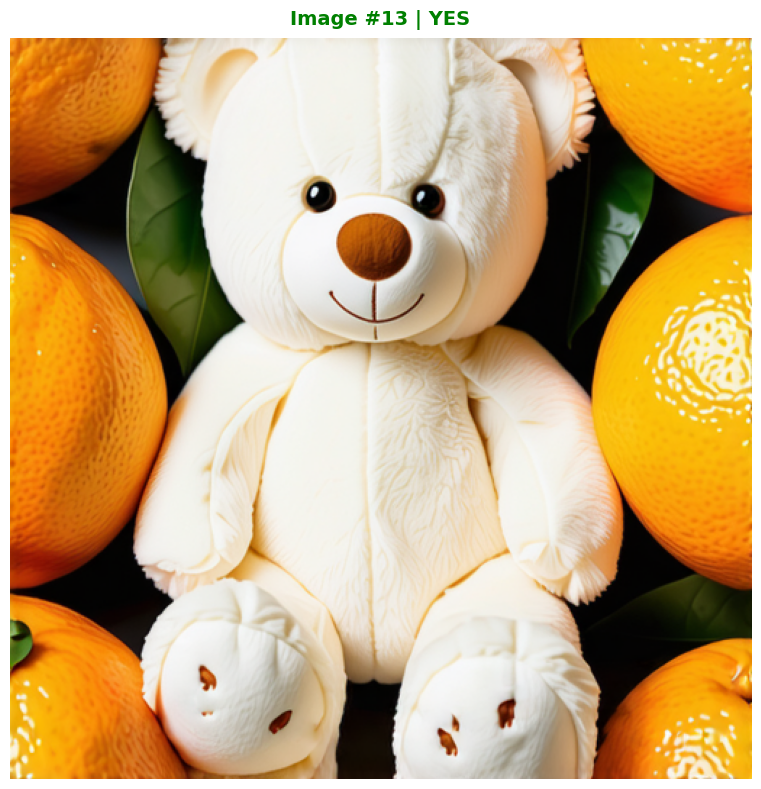

IMAGE #14
Prompt: skis between tennis racket

QWEN Short Answer: YES

QWEN Full Reasoning:
Step 1: The image clearly shows a pair of red skis in the center, flanked on both sides by two blue
tennis rackets. All objects are fully visible against a white background.  Step 2: The skis are
positioned vertically in the center of the frame, with one tennis racket to the left and one to the
right. The skis are spatially located between the two tennis rackets.  Step 3: The image is clear
and the arrangement of the objects is unambiguous.  Conclusion: Yes


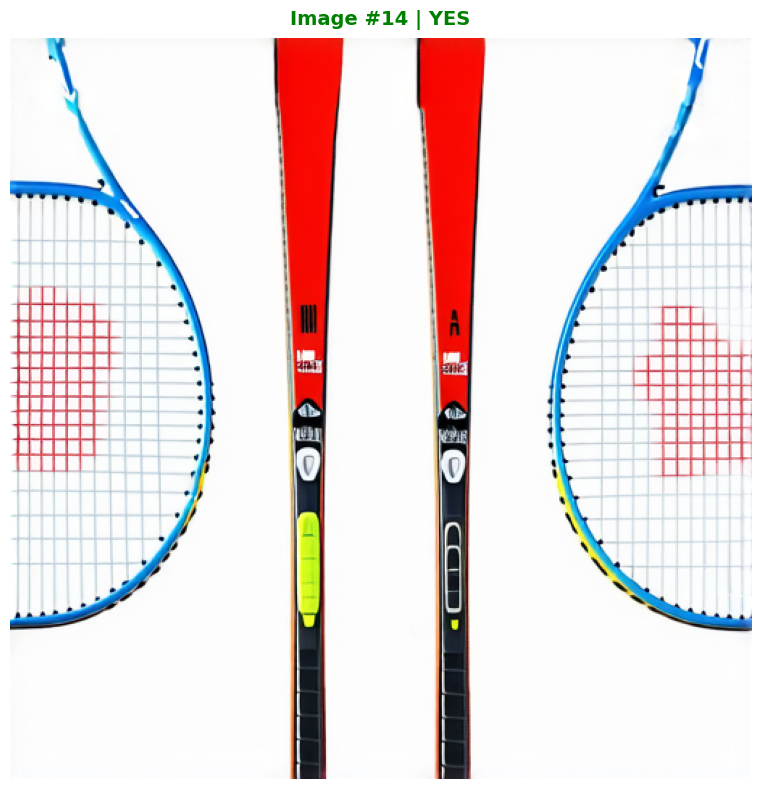

IMAGE #15
Prompt: zebra between bicycle

QWEN Short Answer: YES

QWEN Full Reasoning:
Step 1: The image clearly shows a zebra in the center, with two bicycles positioned on either side
of it. The zebra is facing forward, and both bicycles are visible from the front, with their
handlebars and frames in view.  Step 2: The zebra is located between the two bicycles. The bicycle
on the left is to the zebra's left side, and the bicycle on the right is to its right side. The
zebra is positioned in the space separating the two bicycles, with its body aligned between them.
Step 3: The image is clear and the spatial arrangement is unambiguous.  Conclusion: Yes


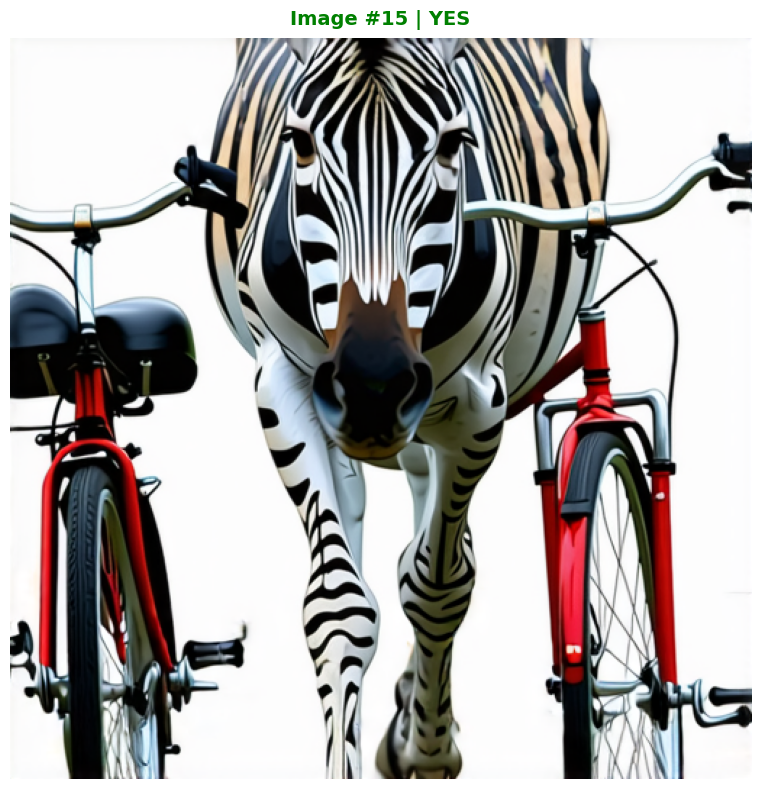

Completed displaying 15 images


In [8]:
visualize_images(model_type='custom', phrase='between', n_images=15)